# 01 · Preprocessing — Li et al. 2019 (Melanoma, MARS-seq)

Load malignant cells, threshold under-populated samples, integrate on `sample`, and decide **Gate 1** (mixed **and** continuous) on the regenerated embedding. Melanoma on MARS-seq carries both strong patient segregation and a technical low-complexity axis, so integration strength is chosen on manifold **continuity**, not a scalar.

In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
for _h in ['harmonypy']:
    logging.getLogger(_h).setLevel(logging.ERROR); logging.getLogger(_h).propagate=False; logging.getLogger(_h).disabled=True

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels deeper than Puram)
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_') -> Li2019_Skin
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category -> Skin
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Li2019_Skin | category: Skin


### Load malignant cells

In [3]:
# load dataset -> select malignant cells (publication cell_type annotation)
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples with malignant cells:', adata.obs['sample'].nunique())
print('expression: X max %.2f  (log1p of normalize_total; MARS-seq UMI counts)' % adata.X.max())
RAW_MALIGNANT = adata.n_obs

Loading ../../../../../../data/unzip/CCCA/Data_Li2019_Skin
Done.
full atlas: (78336, 40979)
malignant: (1160, 40979) | samples with malignant cells: 20
expression: X max 6.05  (log1p of normalize_total; MARS-seq UMI counts)


In [4]:
# MARS-seq provides no cell_cycle_phase -> score it (Tirosh/Regev lists) to check the proliferation confound
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1',
    'HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51',
    'RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO',
    'CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1',
    'KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8',
    'ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
s_g = [g for g in s_genes if g in adata.var_names]; g2m_g = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=s_g, g2m_genes=g2m_g)
adata.obs['cell_cycle_phase'] = adata.obs['phase'].astype(str)
print(f'cell-cycle scored ({len(s_g)} S, {len(g2m_g)} G2M genes):', adata.obs['phase'].value_counts().to_dict())

cell-cycle scored (42 S, 54 G2M genes): {'G1': 761, 'S': 341, 'G2M': 58}


### Per-sample threshold — gap-finding
Look for a **dominant spillover cliff** in the sorted per-sample counts; the premise (C3) is shown to hold before it is used.

In [5]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample malignant counts:', n.values)
print('gap ratios (first 8):', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(min(len(ratios),8))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff ({int(vals[gap])}->{int(vals[gap+1])}) -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR; print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples ({list(keep)}); min per-sample = {int(n[n>=thresh].min())} -> {adata.shape[0]} cells')
AFTER_THRESH = adata.n_obs

sorted per-sample malignant counts: [528 400 154  21  12  10   9   4   4   3   3   2   2   2   1   1   1   1
   1   1]
gap ratios (first 8): ['528->400:1.32', '400->154:2.60', '154->21:7.33', '21->12:1.75', '12->10:1.20', '10->9:1.11', '9->4:2.25', '4->4:1.00']
argmax gap 154->21 (ratio 7.33); top/second = 2.82; dominant cliff = True
dominant spillover cliff (154->21) -> geometric-mean threshold = 56
kept 3/20 samples (['p25', 'p21', 'p26']); min per-sample = 154 -> 1082 cells


### Over-dispersed features -> PCA

In [6]:
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps = 50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance-ratio (first 10):', np.round(vr[:10], 3))
NPC = 20
print('n_pcs =', NPC, '(precedent-bounded 20-40; low scree elbow rejected per eval audit)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 217 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 217
PCA variance-ratio (first 10): [0.365 0.166 0.057 0.035 0.025 0.018 0.014 0.013 0.011 0.009]
n_pcs = 20 (precedent-bounded 20-40; low scree elbow rejected per eval audit)


### Gate-1 integration sweep
Choose `theta` on manifold **continuity** (one connected component, no detached islands), never on the same-sample scalar alone.

In [7]:
def same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def continuity(rep, npcs=NPC):
    sc.pp.neighbors(adata, n_pcs=npcs, use_rep=rep, n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']
    d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    ncomp, lab = connected_components(adj, directed=False)
    main = pd.Series(lab).value_counts().index[0]
    return int((lab!=main).sum()), ncomp
base = same_sample_frac(adata.obsm['X_pca'][:,:NPC])
print('pre-Harmony same-sample fraction %.3f (random baseline ~%.3f)' % (base, 1/adata.obs['sample'].nunique()))
sweep = {}
for th in [2, 5, 10, 20, 40]:
    sc.pp.pca(adata, n_comps=50)
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    frac = same_sample_frac(adata.obsm['X_pca_harmony'][:,:NPC])
    ndet, ncomp = continuity('X_pca_harmony')
    sweep[th] = (round(frac,3), ndet, ncomp)
    print(f'theta={th:2d}: same-sample frac={frac:.3f} | detached cells={ndet} ({ncomp} component(s))')
ok = [th for th in [2,5,10,20,40] if sweep[th][2]==1 and sweep[th][1]==0]
theta = ok[0] if ok else min(sweep, key=lambda t: sweep[t][1])
print(f'selected theta = {theta}: first strength giving ONE continuous component with 0 detached cells')

pre-Harmony same-sample fraction 0.991 (random baseline ~0.333)
theta= 2: same-sample frac=0.787 | detached cells=385 (3 component(s))
theta= 5: same-sample frac=0.613 | detached cells=465 (2 component(s))
theta=10: same-sample frac=0.606 | detached cells=510 (2 component(s))
theta=20: same-sample frac=0.604 | detached cells=457 (2 component(s))
theta=40: same-sample frac=0.696 | detached cells=0 (1 component(s))
selected theta = 40: first strength giving ONE continuous component with 0 detached cells


### Is the low-theta split biology or a technical artifact?
Split the manifold at `theta=10` and rank the genes separating the two islands. A library-complexity axis is fixed by stronger integration, not by deletion.

In [8]:
a10 = adata.copy(); sc.pp.pca(a10, n_comps=50)
sce.pp.harmony_integrate(a10, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(a10, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(a10, spread=1.3, random_state=SEED)
um = a10.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
_, lab = connected_components(adj, directed=False)
a10.obs['island'] = pd.Categorical(pd.Series(lab, index=a10.obs_names).astype(str))
if a10.obs['island'].nunique() > 1:
    sc.tl.rank_genes_groups(a10, 'island', method='wilcoxon', n_genes=15)
    for isl in a10.obs['island'].cat.categories:
        gl = [a10.uns['rank_genes_groups']['names'][i][isl] for i in range(12)]
        n_mt = sum(('MTRNR' in g) or ('MTND' in g) or ('MTATP' in g) or g.startswith('RP11') or g.startswith('RP5') for g in gl)
        m = (lab==int(isl))
        print(f'island {isl} (n={int(m.sum())}) markers: {gl}')
        print(f'   -> {n_mt}/12 mitochondrial-pseudogene / lincRNA (low-complexity MARS-seq markers)')
print('the low-theta split is a technical low-complexity axis -> resolved by stronger integration, not a biological')
print('discontinuity (islands share module means, samples and cell cycle) -> no island removed')

island 0 (n=572) markers: ['VIM', 'LGALS1', 'S100A10', 'TPT1', 'EEF1A1P5', 'RPL27', 'S100A6', 'LMNA', 'TMSB10', 'SERPINE2', 'RTN4', 'EIF1']
   -> 0/12 mitochondrial-pseudogene / lincRNA (low-complexity MARS-seq markers)
island 1 (n=510) markers: ['hsa-mir-6723', 'RP5-857K21.11', 'MTATP6P1', 'RP5-857K21.7', 'RP11-750B16.1', 'RP11-475J5.4', 'MTRNR2L12', 'MTRNR2L8', 'MTRNR2L2', 'MTND4P12', 'MTRNR2L1', 'MTATP8P1']
   -> 11/12 mitochondrial-pseudogene / lincRNA (low-complexity MARS-seq markers)
the low-theta split is a technical low-complexity axis -> resolved by stronger integration, not a biological
discontinuity (islands share module means, samples and cell cycle) -> no island removed


### Refit at the derived theta -> confirm one continuous component

In [9]:
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
ndet = int((lab!=pd.Series(lab).value_counts().index[0]).sum())
c = um - um.mean(0); _,sv,_ = np.linalg.svd(c, full_matrices=False)
print(f'theta={theta}: {ncomp} connected component(s), {ndet} detached cells; UMAP aspect = {sv[0]/sv[1]:.2f} (elongated)')
AFTER_ISLAND = adata.n_obs

theta=40: 1 connected component(s), 0 detached cells; UMAP aspect = 2.84 (elongated)


### Embryonic modules + proliferation-decouple check
Score Gast/pSom/Crest with the union control pool, graph-smooth for geography, and confirm the axis is developmental (not a cell-cycle gradient).

In [10]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab_ in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab_, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab_}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab_ in enumerate(['Gast','pSom','Crest']): adata.obs[lab_+'_sm'] = S[:,j]
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  corr(prolif, {m}) = {np.corrcoef(adata.obs["prolif_score"], adata.obs[m])[0,1]:+.2f}')
print('modules cell-cycle-decoupled (|corr|<=0.15) -> developmental axis, not proliferation')

Gast: 64/81 genes present
pSom: 75/98 genes present
Crest: 96/104 genes present
raw module means: {'Gast': -0.0152, 'pSom': 0.0158, 'Crest': -0.0022}
  corr(prolif, Gast_sm) = -0.14
  corr(prolif, pSom_sm) = +0.06
  corr(prolif, Crest_sm) = +0.05
modules cell-cycle-decoupled (|corr|<=0.15) -> developmental axis, not proliferation


### Gate 1 = GO

In [11]:
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre  = np.median(ilisi(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp} samples')
print(f'GATE 1 = GO: at theta={theta} the {nsamp} samples share ONE continuous component ({ncomp} comp, {ndet} detached),')
print('  sample- and cell-cycle-mixed throughout; low-theta islands were a technical low-complexity axis (integrated,')
print('  not deleted). NB Harmony KMeans is not seed-deterministic -> counts may shift a few cells between runs;')
print('  the single-component call is robust.')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=40) 2.07 of 3 samples
GATE 1 = GO: at theta=40 the 3 samples share ONE continuous component (1 comp, 0 detached),
  sample- and cell-cycle-mixed throughout; low-theta islands were a technical low-complexity axis (integrated,
  not deleted). NB Harmony KMeans is not seed-deterministic -> counts may shift a few cells between runs;
  the single-component call is robust.


### House linear layout (reused by all downstream figures)

In [12]:
origin_score = adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values - adata.obs['Crest_sm'].values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot), -np.sin(-th_rot)],[np.sin(-th_rot), np.cos(-th_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('stored X_umap_lin: Gast/pSom-high origin on left, neural-crest terminus on right')

stored X_umap_lin: Gast/pSom-high origin on left, neural-crest terminus on right


### Save processed manifold + samples.pdf

In [13]:
protect = {'sample','celltype','cell_type','cell_subtype','cell_cycle_phase','phase','source','location','stage','patient','amp_batch'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s_ = adata.obs[col]
    if s_.dtype == object:
        conv = pd.to_numeric(s_, errors='coerce')
        adata.obs[col] = conv if (s_.notna().sum()>0 and conv.notna().sum()>=0.9*s_.notna().sum()) else s_.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape, '| counts raw', RAW_MALIGNANT, '-> threshold', AFTER_THRESH, '-> island', AFTER_ISLAND)

saved processed.h5ad (1082, 18161) | counts raw 1160 -> threshold 1082 -> island 1082


saved samples.pdf | cells: 1082


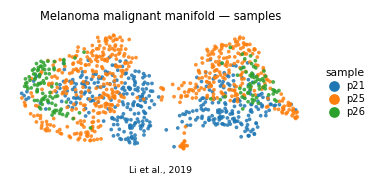

In [14]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xy = plot.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=24, alpha=.85, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.3, fontsize=6.5, title='sample', title_fontsize=7)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Melanoma malignant manifold — samples', size=7.5)
ax.text(.5, -.13, 'Li et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])